<!-- Importing libraries -->

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [58]:
sns.set_style("whitegrid")

plt.rcParams['figure.figsize'] = (10, 6)

plt.rcParams['figure.dpi'] = 100

<!-- Loading dataset -->

In [59]:

df = pd.read_csv("../dataset/StudentsPerformance.csv")

print('dataset is loaded successfully!')


dataset is loaded successfully!


<!-- DATA INSPECTION: understanding dataset -->

In [60]:
# Display Dataset
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [61]:
# Data Understanding
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1000
Number of Columns: 8


<!-- DATA CLEANING: to ensure data consistency and reliablility -->

In [62]:
# Dataset Information
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


<!-- Statistical Analysis  -->

In [64]:
#  MISSING VALUES / data cleaning
df.isnull().sum()


gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [11]:
# dublicate records
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


<!--  -->

In [13]:
print(df.dtypes)
df.columns = df.columns.str.strip().str.replace(" ", "_").str.lower()

print(df.columns.tolist())

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object
['gender', 'race/ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


<!-- Statistical Analysis  -->

In [65]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


<!-- Exploratory data analysis -->

In [14]:
score_columns = ['math_score', 'reading_score', 'writing_score']

for col in score_columns:
    print(col, df[col].between(0, 100).all())

math_score True
reading_score True
writing_score True


<!-- Subject-wise Average -->

In [15]:
subjects = ['math_score', 'reading_score', 'writing_score']

subject_average = df[subjects].mean()

print(subject_average.round(2))

math_score       66.09
reading_score    69.17
writing_score    68.05
dtype: float64


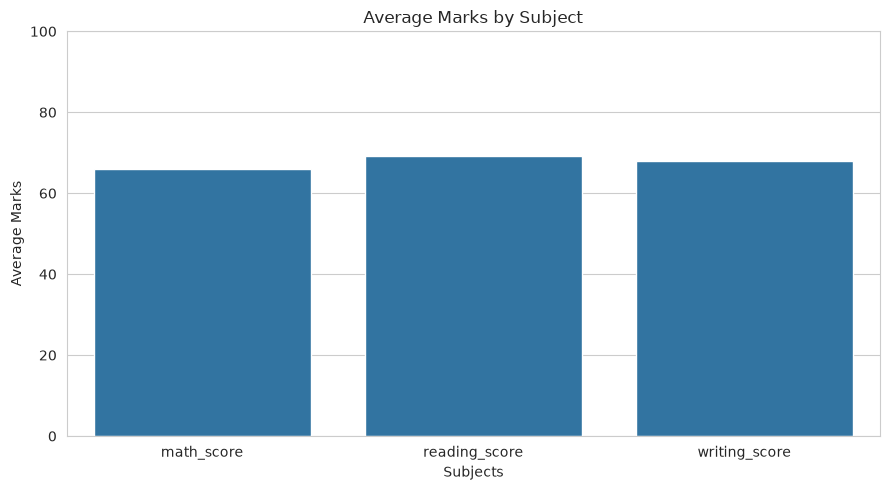

In [ ]:
#
plt.figure(figsize=(9, 5))

sns.barplot(
    x=subject_average.index,
    y=subject_average.values
)

plt.title("Average Marks by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.ylim(0, 100)

plt.tight_layout()
plt.savefig("../visualizations/subject_average.png")
plt.show()

<!--   Gender-wise performance -->

In [ ]:

gender_analysis = df.groupby('gender')[subjects].mean()

print(gender_analysis.round(2))

        math_score  reading_score  writing_score
gender                                          
female       63.63          72.61          72.47
male         68.73          65.47          63.31


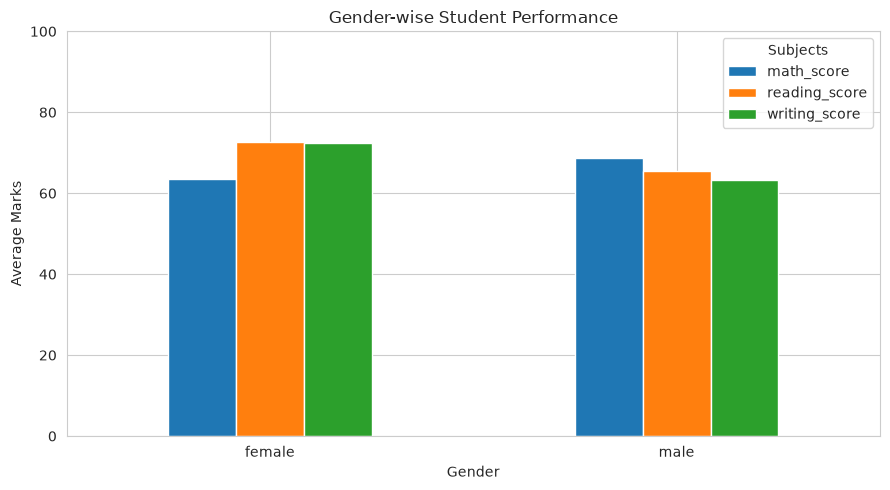

In [20]:
# Gender-wise average marks
gender_analysis.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Gender-wise Student Performance")
plt.xlabel("Gender")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(title="Subjects")
plt.tight_layout()
plt.savefig("../visualizations/gender_performance.png")
plt.show()

<!--   Score Distribution -->

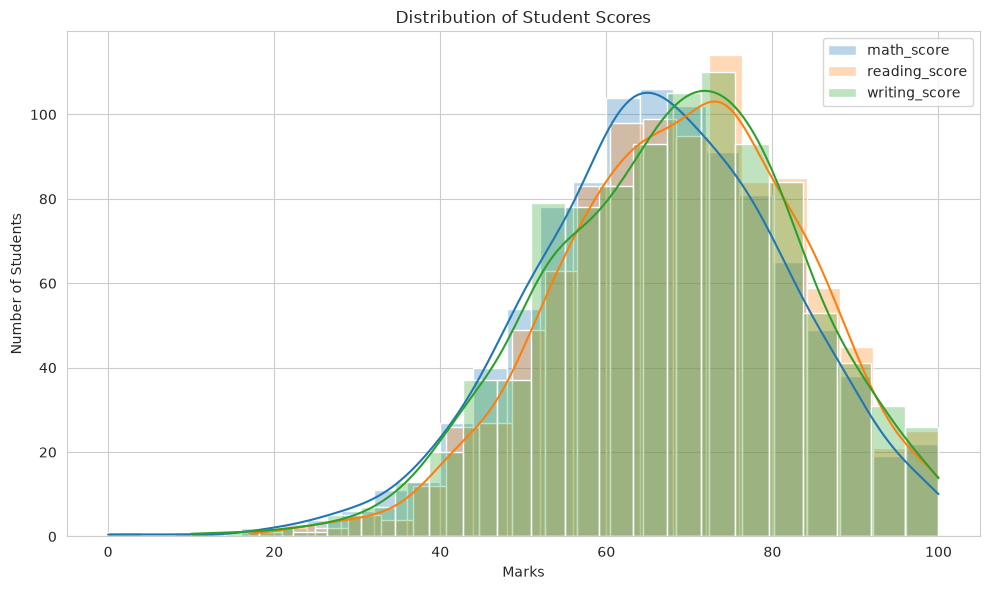

In [ ]:

plt.figure(figsize=(10, 6))

for col in subjects:
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        label=col,
        alpha=0.3
    )

plt.title("Distribution of Student Scores")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.legend()

plt.tight_layout()
plt.savefig("../visualizations/score_distribution.png")
plt.show()

<!-- Math vs Reading relationship -->

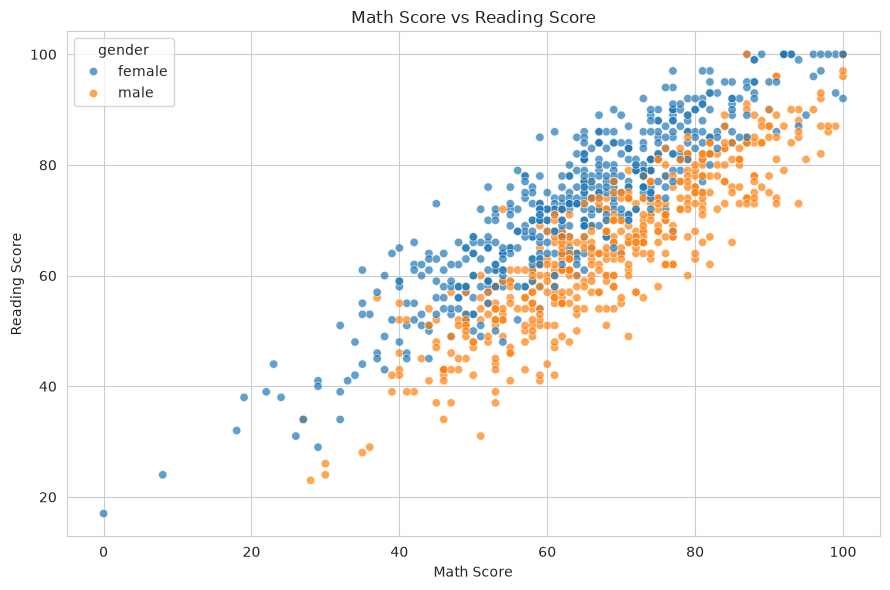

In [ ]:

# Scatter plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='math_score',
    y='reading_score',
    hue='gender',
    alpha=0.7
)

plt.title("Math Score vs Reading Score")
plt.xlabel("Math Score")
plt.ylabel("Reading Score")

plt.tight_layout()
plt.savefig("../visualizations/math_reading_scatter.png")
plt.show()

<!-- Correlation analysis -->

In [23]:
correlation = df[subjects].corr()

print(correlation.round(2))

               math_score  reading_score  writing_score
math_score           1.00           0.82           0.80
reading_score        0.82           1.00           0.95
writing_score        0.80           0.95           1.00


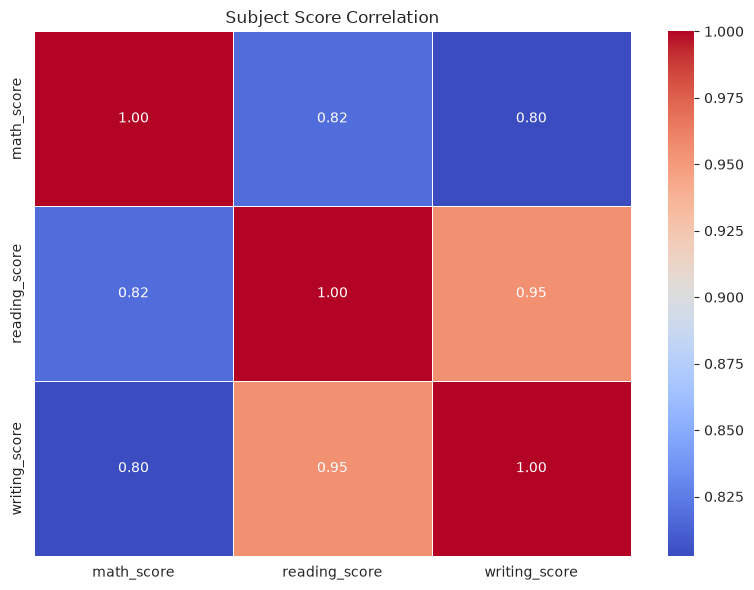

In [24]:
# Correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Subject Score Correlation")

plt.tight_layout()
plt.savefig("../visualizations/correlation_heatmap.png")
plt.show()

<!--  Test preparation analysis -->

In [25]:
#  Test preparation analysis
prep_analysis = df.groupby(
    'test_preparation_course'
)[subjects].mean()

print(prep_analysis.round(2))

                         math_score  reading_score  writing_score
test_preparation_course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50


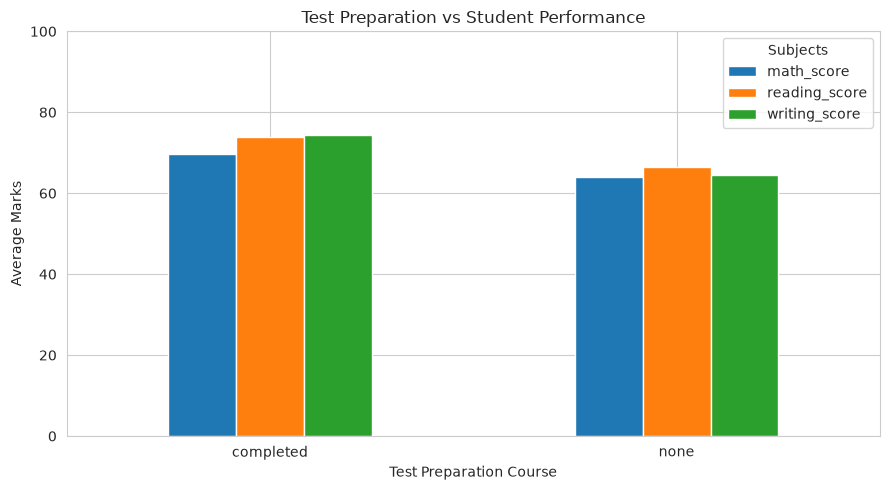

In [26]:
# Test preparation comparison
prep_analysis.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Test Preparation vs Student Performance")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(title="Subjects")
plt.tight_layout()
plt.savefig("../visualizations/test_preparation.png")
plt.show()

<!-- Lunch category analysis -->

In [27]:
# Lunch category analysis
lunch_analysis = df.groupby('lunch')[subjects].mean()

print(lunch_analysis.round(2))

              math_score  reading_score  writing_score
lunch                                                 
free/reduced       58.92          64.65          63.02
standard           70.03          71.65          70.82


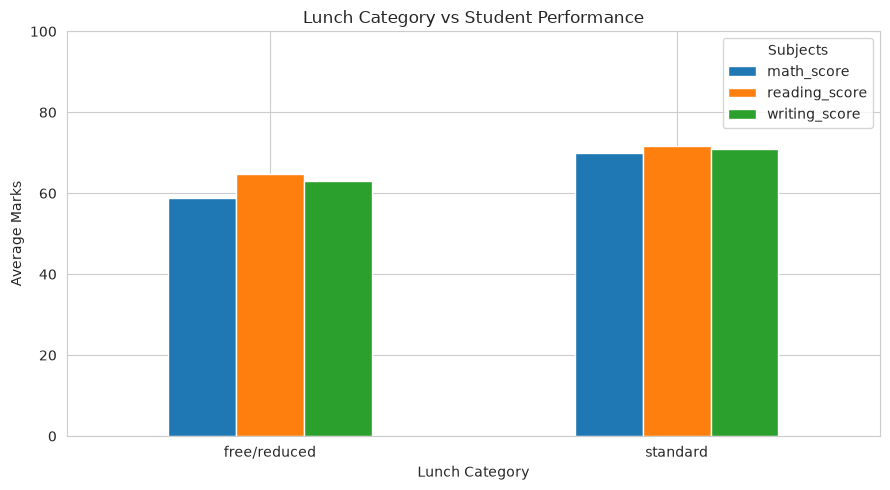

In [28]:
# Lunch category comparison
lunch_analysis.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Lunch Category vs Student Performance")
plt.xlabel("Lunch Category")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(title="Subjects")
plt.tight_layout()
plt.savefig("../visualizations/lunch_analysis.png")
plt.show()

<!-- Parental education analysis -->

In [ ]:
#  parental education score
parent_analysis = df.groupby(
    'parental_level_of_education'
)[subjects].mean()

print(parent_analysis.round(2))

                             math_score  reading_score  writing_score
parental_level_of_education                                          
associate's degree                67.88          70.93          69.90
bachelor's degree                 69.39          73.00          73.38
high school                       62.14          64.70          62.45
master's degree                   69.75          75.37          75.68
some college                      67.13          69.46          68.84
some high school                  63.50          66.94          64.89


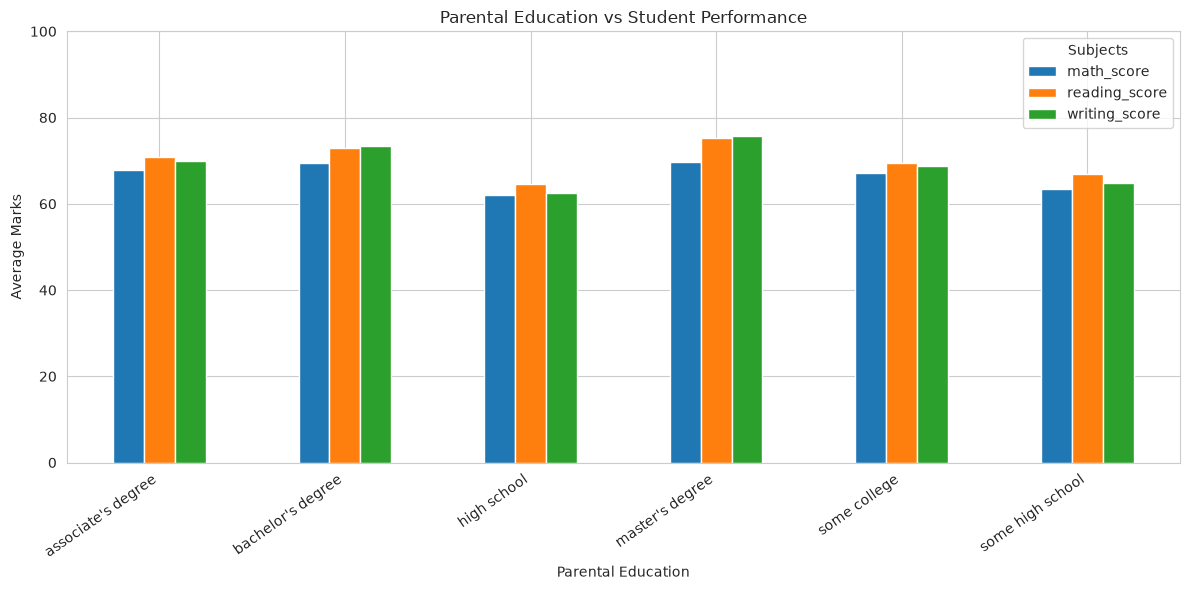

In [30]:
#  Parental education comparison
parent_analysis.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Parental Education vs Student Performance")
plt.xlabel("Parental Education")
plt.ylabel("Average Marks")
plt.xticks(rotation=35, ha='right')
plt.ylim(0, 100)

plt.legend(title="Subjects")
plt.tight_layout()
plt.savefig("../visualizations/parental_education.png")
plt.show()

<!-- Overall student performance -->

In [31]:
df['average_score'] = df[subjects].mean(axis=1).round(2)

print(df[['math_score', 'reading_score',
          'writing_score', 'average_score']].head())

   math_score  reading_score  writing_score  average_score
0          72             72             74          72.67
1          69             90             88          82.33
2          90             95             93          92.67
3          47             57             44          49.33
4          76             78             75          76.33


In [32]:
print("Overall Class Average:",
      round(df['average_score'].mean(), 2))

print("Highest Student Average:",
      df['average_score'].max())

print("Lowest Student Average:",
      df['average_score'].min())

Overall Class Average: 67.77
Highest Student Average: 100.0
Lowest Student Average: 9.0


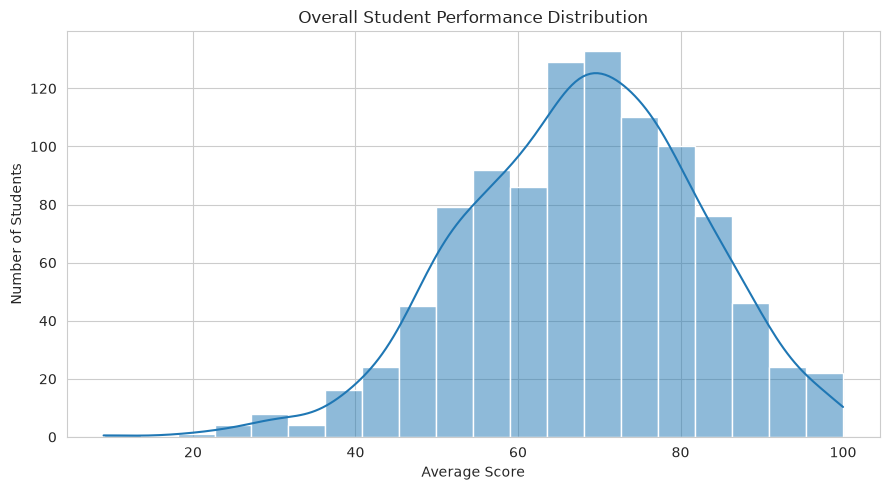

In [33]:
# : Overall score distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='average_score',
    bins=20,
    kde=True
)

plt.title("Overall Student Performance Distribution")
plt.xlabel("Average Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("../visualizations/overall_performance.png")
plt.show()

<!-- Result Summary – Student Performance Analysis -->


<!-- The analysis of 1,000 students shows the following key results:
1. Subject-wise average scores
Subject	Average Score
Math	66.09
Reading	69.17
Writing	68.05
Overall Average	67.77

Reading has the highest average score, followed by Writing and Math.

# @ Key findings


1. Gender: Male students have a higher average in Math, while female students have higher average Reading and Writing scores.
2. Test preparation: Students who completed the test preparation course have higher average scores across subjects.
3. Lunch type: Students with standard lunch have higher average scores than students with free/reduced lunch.
4. Score correlation: Reading and Writing scores have a strong positive correlation of approximately 0.96.
5. Overall performance: The average score across all three subjects is approximately 67.77. -->


<!-- Conclusion -->


<!-- 

The Student Performance Analysis project explores the academic performance of 1,000 students using Python.

The analysis was performed using Pandas, NumPy, Matplotlib, and Seaborn.

The major findings are:

1. Reading has the highest average score among the three subjects.
2. Mathematics has the lowest average score.
3. Female students perform better in Reading and Writing on average, while male students have a higher average in Mathematics.
4. Students who completed the test preparation course have higher average scores across all three subjects.
5. Reading and Writing scores show a strong positive correlation.
6. Student performance also varies across lunch and parental education categories.

This project helped demonstrate how Python can be used for data cleaning, exploratory data analysis, statistical analysis, and data visualization.

-->